In [2]:
from google.colab import files

uploaded = files.upload()


Saving deceptive-opinion.csv to deceptive-opinion.csv


In [3]:
import pandas as pd

df = pd.read_csv('deceptive-opinion.csv')

# Display first five rows
df.head()


,deceptive,hotel,polarity,source,text
0,truthful,conrad,positive,TripAdvisor,We stayed for a one night getaway with family ...
1,truthful,hyatt,positive,TripAdvisor,Triple A rate with upgrade to view room was le...
2,truthful,hyatt,positive,TripAdvisor,This comes a little late as I'm finally catchi...
3,truthful,omni,positive,TripAdvisor,The Omni Chicago really delivers on all fronts...
4,truthful,hyatt,positive,TripAdvisor,I asked for a high floor away from the elevato...


In [4]:
import re
from pathlib import Path

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer

In [6]:
DATA_PATH = Path("deceptive-opinion.csv")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True) # Create a folder for outputs
RANDOM_STATE = 9000 # Random seed
N_SPLITS = 5 # For 5-fold cross-validation

In [7]:
# Step 1: Load dataset
df = pd.read_csv(DATA_PATH)

In [8]:
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (1600, 5)
  deceptive   hotel  polarity       source  \
0  truthful  conrad  positive  TripAdvisor   
1  truthful   hyatt  positive  TripAdvisor   
2  truthful   hyatt  positive  TripAdvisor   
3  truthful    omni  positive  TripAdvisor   
4  truthful   hyatt  positive  TripAdvisor   

                                                text  
0  We stayed for a one night getaway with family ...  
1  Triple A rate with upgrade to view room was le...  
2  This comes a little late as I'm finally catchi...  
3  The Omni Chicago really delivers on all fronts...  
4  I asked for a high floor away from the elevato...  


In [9]:
# Data inspection
print("\nMissing values:")
print(df.isna().sum())


Missing values:
deceptive    0
hotel        0
polarity     0
source       0
text         0
dtype: int64


In [10]:
print("\nClass distribution:")
print(df["deceptive"].value_counts())


Class distribution:
deceptive
truthful     800
deceptive    800
Name: count, dtype: int64


In [11]:
print("\nSentiment distribution:")
print(df["polarity"].value_counts())


Sentiment distribution:
polarity
positive    800
negative    800
Name: count, dtype: int64


In [12]:
print("\nNumber of hotels:", df["hotel"].nunique())


Number of hotels: 20


In [13]:
# Step 2: Check duplicates and label consistency
print("Duplicate reviews:", df.duplicated(subset=["text"]).sum()) # Check duplicate reviews


Duplicate reviews: 4


In [14]:
conflicts = df.groupby("text")["deceptive"].nunique() # Check conflicting labels
print("Conflicting labels:", (conflicts > 1).sum())

Conflicting labels: 0


deceptive         deceptive  truthful
hotel                                
affinia                  40        40
allegro                  40        40
amalfi                   40        40
ambassador               40        40
conrad                   40        40
fairmont                 40        40
hardrock                 40        40
hilton                   40        40
homewood                 40        40
hyatt                    40        40
intercontinental         40        40
james                    40        40
knickerbocker            40        40
monaco                   40        40
omni                     40        40
palmer                   40        40
sheraton                 40        40
sofitel                  40        40
swissotel                40        40
talbott                  40        40


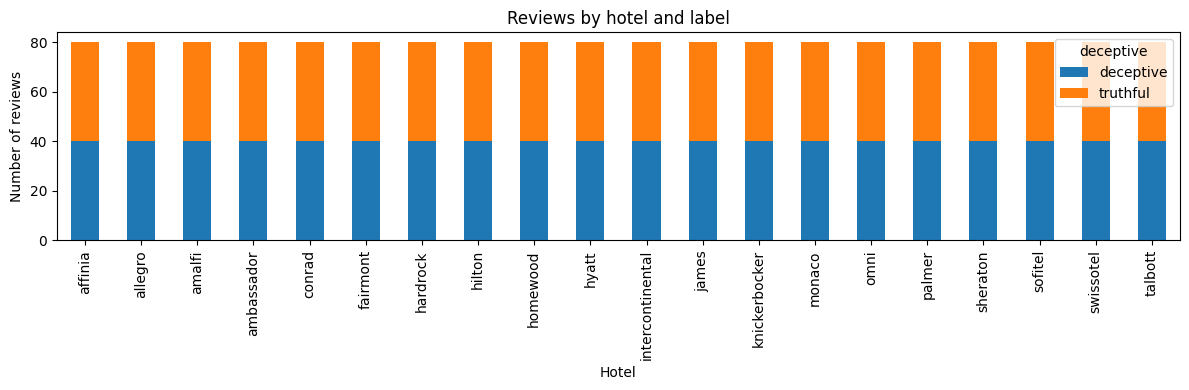

In [15]:
# Step 3: EDA
# Reviews by hotel
hotel_counts = df.groupby(["hotel", "deceptive"]).size().unstack(fill_value=0)
print(hotel_counts)
hotel_counts.plot(kind="bar", stacked=True, figsize=(12, 4), title="Reviews by hotel and label")
plt.xlabel("Hotel")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

In [16]:
# Review length Distribution
df["word_count"] = df["text"].fillna("").str.split().str.len()
print(df.groupby("deceptive")["word_count"].describe().round(1))

           count   mean   std   min   25%    50%    75%    max
deceptive                                                     
deceptive  800.0  146.6  84.8  25.0  88.0  125.0  182.0  784.0
truthful   800.0  150.9  89.8  30.0  89.0  130.0  183.0  749.0


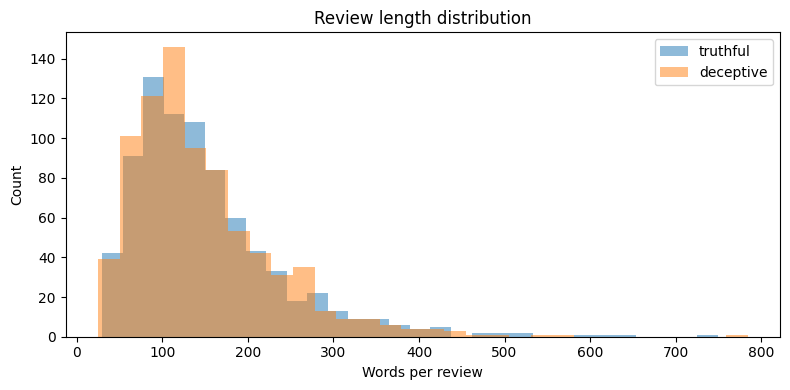

In [17]:
plt.figure(figsize=(8, 4))
for label in ["truthful", "deceptive"]:
    plt.hist(df.loc[df["deceptive"] == label, "word_count"], bins=30, alpha=0.5, label=label)
plt.xlabel("Words per review")
plt.ylabel("Count")
plt.title("Review length distribution")
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
# Step 4: Clean data and prepare labels
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

In [19]:
# Remove missing and empty reviews
clean_df = df.copy()
clean_df = clean_df.dropna(subset=["text", "deceptive", "hotel"])

clean_df["review_text"] = clean_df["text"].apply(clean_text)
clean_df = clean_df[clean_df["review_text"].str.len() > 0].copy()


In [20]:
# Encode labels
clean_df["label"] = clean_df["deceptive"].map({
    "truthful": 0,
    "deceptive": 1
})

In [21]:
# Validate labels and reset index
assert clean_df["label"].notna().all()
clean_df["label"] = clean_df["label"].astype(int)
clean_df = clean_df.reset_index(drop=True)

In [22]:
# Save cleaned data to outputs
clean_df.to_csv(OUTPUT_DIR / "cleaned_reviews.csv", index=False)

In [23]:
# Step 5: Hotel-grouped 5-fold cross-validation
# Prepare text, labels, and hotel groups
X_text = clean_df["review_text"]
y = clean_df["label"]
groups = clean_df["hotel"]

In [24]:
# Create hotel-grouped 5-fold splits
cv = StratifiedGroupKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)
folds = list(cv.split(X_text, y, groups=groups))

In [25]:
# Check hotel leakage
fold_summary = []
fold_rows = []
for fold_id, (train_idx, val_idx) in enumerate(folds, start=1):
    train_hotels = set(groups.iloc[train_idx])
    val_hotels = set(groups.iloc[val_idx])
    assert train_hotels.isdisjoint(val_hotels)
    fold_summary.append({
        "fold": fold_id,
        "train_reviews": len(train_idx),
        "val_reviews": len(val_idx),
        "train_hotels": len(train_hotels),
        "val_hotels": len(val_hotels),
        "train_deceptive_rate": round(y.iloc[train_idx].mean(), 3),
        "val_deceptive_rate": round(y.iloc[val_idx].mean(), 3),
    })
    fold_rows.extend(
        {"row_index": int(idx), "fold": fold_id}
        for idx in val_idx
    )

In [26]:
summary_df = pd.DataFrame(fold_summary)
print(summary_df)

   fold  train_reviews  val_reviews  train_hotels  val_hotels  \
0     1           1280          320            16           4   
1     2           1280          320            16           4   
2     3           1280          320            16           4   
3     4           1280          320            16           4   
4     5           1280          320            16           4   

   train_deceptive_rate  val_deceptive_rate  
0                   0.5                 0.5  
1                   0.5                 0.5  
2                   0.5                 0.5  
3                   0.5                 0.5  
4                   0.5                 0.5  


In [27]:
# Save fold assignments
fold_assignment = pd.DataFrame(fold_rows).sort_values("row_index")
fold_assignment.to_csv(OUTPUT_DIR / "fold_assignments.csv", index=False)

In [28]:
# Step 6: TF-IDF
def get_fold_features(clean_df, train_idx, val_idx):
    vectorizer = TfidfVectorizer(
        ngram_range=(1, 2), # Extract unigrams and bigrams
        min_df=2,
        max_df=0.95,
        sublinear_tf=True,
    )
    # Fit TF-IDF on training data
    X_train = vectorizer.fit_transform(clean_df.iloc[train_idx]["review_text"])
    X_val = vectorizer.transform(clean_df.iloc[val_idx]["review_text"])

    # Extract labels
    y_train = clean_df.iloc[train_idx]["label"].to_numpy()
    y_val = clean_df.iloc[val_idx]["label"].to_numpy()

    return X_train, X_val, y_train, y_val, vectorizer

In [29]:
# Generate TF-IDF features for all five folds
fold_features = []

for train_idx, val_idx in folds:
    X_train, X_val, y_train, y_val, vectorizer = get_fold_features(
        clean_df, train_idx, val_idx
    )

    fold_features.append((X_train, X_val, y_train, y_val))

In [30]:
# ### Preprocessing Summary
#
# **Files provided:**
# - `cleaned_reviews.csv`: Cleaned review texts and encoded labels (0 = truthful, 1 = deceptive).
# - `fold_assignments.csv`: Predefined hotel-grouped 5-fold cross-validation splits.
#
# **Preprocessing completed:**
# - Data cleaning and label encoding.
# - Hotel-grouped 5-fold cross-validation.
# - TF-IDF feature extraction for all five folds.

# **MLP**

In [31]:
# Step 7MLP: Train and evaluate an MLP model
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

mlp_results = []
all_y_true = []
all_y_pred = []

for fold_id, (X_train, X_val, y_train, y_val) in enumerate(fold_features, start=1):
    mlp = MLPClassifier(
        hidden_layer_sizes=(150,),  # One hidden layer with 150 neurons
        activation="relu",
        solver="adam",
        alpha=0.0001,               # L2 regularization
        batch_size=32,
        learning_rate_init=0.001,
        max_iter=300,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=15,
        random_state=RANDOM_STATE
    )
     # Train the neural network using the training reviews
    mlp.fit(X_train, y_train)

    # Predict labels for the held-out validation reviews
    y_pred = mlp.predict(X_val)

    all_y_true.extend(y_val)
    all_y_pred.extend(y_pred)

    mlp_results.append({
        "fold": fold_id,
        "accuracy": accuracy_score(y_val, y_pred),
        "precision": precision_score(y_val, y_pred, zero_division=0),
        "recall": recall_score(y_val, y_pred, zero_division=0),
        "f1": f1_score(y_val, y_pred, zero_division=0),
        "iterations": mlp.n_iter_
    })

In [32]:
# Display performance for each fold
mlp_results_df = pd.DataFrame(mlp_results)
print("\nMLP results by fold:")
print(mlp_results_df.round(3))


MLP results by fold:
   fold  accuracy  precision  recall     f1  iterations
0     1     0.878      0.912   0.838  0.873          21
1     2     0.916      0.918   0.912  0.915          18
2     3     0.847      0.849   0.844  0.846          21
3     4     0.912      0.912   0.912  0.912          17
4     5     0.884      0.892   0.875  0.883          18


In [33]:
# Mean and standard deviation across the five folds
print("\nMean cross-validation performance:")
print(mlp_results_df[["accuracy", "precision", "recall", "f1"]].agg(["mean", "std"]).round(3))



Mean cross-validation performance:
      accuracy  precision  recall     f1
mean     0.888      0.897   0.876  0.886
std      0.028      0.028   0.036  0.029


In [34]:
# Overall report using predictions from all five held-out folds
print("\nOverall classification report:")
print(classification_report(
    all_y_true,
    all_y_pred,
    labels=[0, 1],
    target_names=["truthful", "deceptive"],
    zero_division=0
))


Overall classification report:
              precision    recall  f1-score   support

    truthful       0.88      0.90      0.89       800
   deceptive       0.90      0.88      0.89       800

    accuracy                           0.89      1600
   macro avg       0.89      0.89      0.89      1600
weighted avg       0.89      0.89      0.89      1600



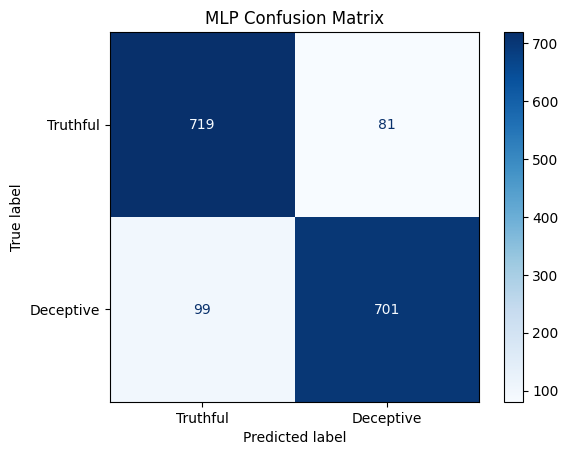

Confusion Matrix:
[[719  81]
 [ 99 701]]


In [35]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate confusion matrix
cm = confusion_matrix(
    all_y_true,
    all_y_pred,
    labels=[0, 1]
)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Truthful", "Deceptive"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("MLP Confusion Matrix")
plt.show()

print("Confusion Matrix:")
print(cm)

In [36]:
# Verify that each hotel is separated
for fold_id, (train_idx, val_idx) in enumerate(folds, start=1):

    train_hotels = set(groups.iloc[train_idx])
    val_hotels = set(groups.iloc[val_idx])

    assert train_hotels.isdisjoint(val_hotels)

    print(f"Fold {fold_id}: No hotel leakage")

# Verify every review is used for validation exactly once
validation_indices = [
    idx
    for _, val_idx in folds
    for idx in val_idx
]

assert sorted(validation_indices) == list(range(len(clean_df)))

print("All reviews appear in validation exactly once.")
print("Cross-validation checks passed.")

Fold 1: No hotel leakage
Fold 2: No hotel leakage
Fold 3: No hotel leakage
Fold 4: No hotel leakage
Fold 5: No hotel leakage
All reviews appear in validation exactly once.
Cross-validation checks passed.


# New Section